<a href="https://colab.research.google.com/github/english075social/Clase80/blob/main/Copia_de_Peliculas__proyecto_nuevo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Aviso: No se encontró 'catalogo_streaming.csv'. Generando muestra en memoria...

--- PASO 1: PRIMERAS FILAS DEL DATASET (Luis) ---
            titulo tipo_contenido genero_principal  año_estreno  \
0     Plaza Sésamo          Serie         Infantil       2018.0   
1  Stranger Things          Serie  Ciencia Ficción       2019.0   
2        Inception       Película  Ciencia Ficción       2010.0   
3             Dark          Serie         Misterio       2017.0   
4      El Marginal          Serie            Drama       2016.0   

      pais_origen  duracion_min  
0          México            30  
1  Estados Unidos            50  
2  Estados Unidos           148  
3        Alemania            60  
4       Argentina            45  

El catálogo contiene 7 filas (títulos) y 6 columnas.

--- PASO 2: REVISIÓN DE DATOS AUSENTES (Luis) ---
titulo              0
tipo_contenido      0
genero_principal    0
año_estreno         1
pais_origen         0
duracion_min        0
dtype: int64

Variedad de

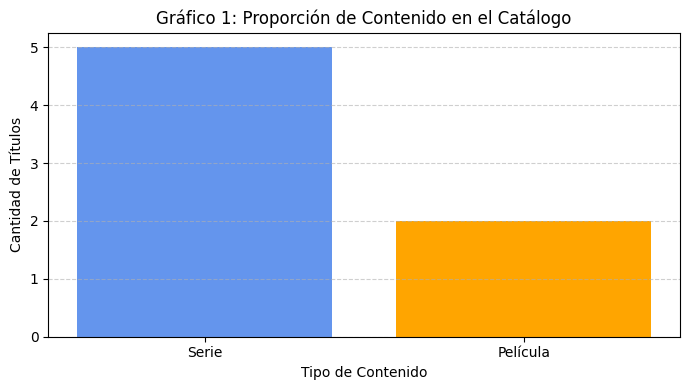

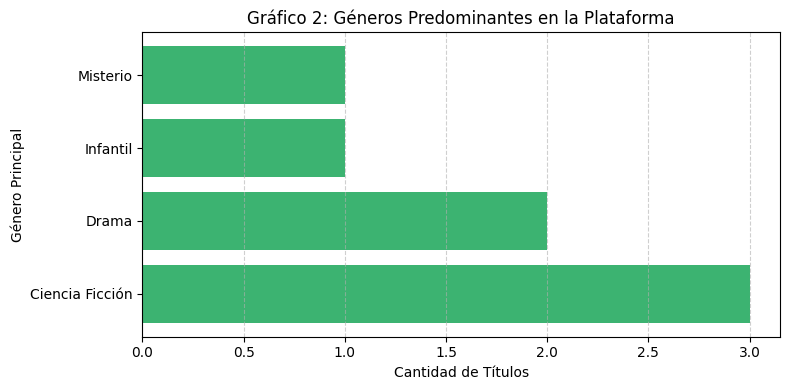

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# -*- coding: utf-8 -*-
"""Peliculas_proyecto.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1-b7QRZ-r5pVg69YZTpwdBQ0kGH9Fy6uX
"""

# =============================================================================
# PLAN DEFINITIVO DE INVESTIGACIÓN Y MINI CLASE DIDÁCTICA DE DATOS
# Proyecto: ¿Qué películas y series predominan en una plataforma de streaming?
# Equipo: Luis (Datos), Karen (Análisis), Milena (Visualización y Enseñanza)
# =============================================================================

# 'import' es la palabra clave en Python para cargar librerías (módulos con herramientas externas).
# 'as' nos permite crear un alias o apodo corto para no tener que escribir el nombre completo de la librería cada vez.
import matplotlib.pyplot as plt  # Importamos el módulo de gráficos de Matplotlib con el alias 'plt'.
import pandas as pd  # Importamos la librería de análisis de datos Pandas con el alias 'pd'.

# =============================================================================
# PASO 1 Y 2: COMPRENSIÓN, CARGA Y LIMPIEZA DE DATOS (Responsable: LUIS)
# =============================================================================

# 'try' inicia un bloque de prueba. Python intentará ejecutar el código dentro de este bloque.
try:
    # 'pd.read_csv()' busca y lee un archivo CSV y lo convierte en una tabla de Pandas (DataFrame).
    # 'df_catalogo' es la variable que almacena nuestro DataFrame.
    df_catalogo = pd.read_csv("catalogo_streaming.csv")
    print("¡Éxito! Dataset cargado desde 'catalogo_streaming.csv'.")

# 'except' captura el error 'FileNotFoundError' en caso de que el archivo CSV no exista en la carpeta.
except FileNotFoundError:
    print(
        "Aviso: No se encontró 'catalogo_streaming.csv'. Generando muestra en memoria..."
    )

    # 'datos_base' es una variable de tipo diccionario creada con llaves '{}'.
    datos_base = {
        # Los corchetes '[]' contienen una lista: una secuencia ordenada de datos separados por comas.
        "titulo": [
            "Plaza Sésamo",
            "Stranger Things",
            "Inception",
            "Dark",
            "El Marginal",
            "Crown",
            "Interstellar",
        ],
        "tipo_contenido": [
            "Serie",
            "Serie",
            "Película",
            "Serie",
            "Serie",
            "Serie",
            "Película",
        ],
        "genero_principal": [
            "Infantil",
            "Ciencia Ficción",
            "Ciencia Ficción",
            "Misterio",
            "Drama",
            "Drama",
            "Ciencia Ficción",
        ],
        # 'None' es la palabra clave en Python que representa un valor nulo o dato ausente.
        "año_estreno": [2018, 2019, 2010, 2017, 2016, None, 2014],
        "pais_origen": [
            "México",
            "Estados Unidos",
            "Estados Unidos",
            "Alemania",
            "Argentina",
            "Reino Unido",
            "Estados Unidos",
        ],
        "duracion_min": [30, 50, 148, 60, 45, 58, 169],
    }
    # 'pd.DataFrame()' transforma el diccionario en un DataFrame (tabla estructurada).
    df_catalogo = pd.DataFrame(datos_base)

# '.head()' muestra las primeras 5 filas del DataFrame para realizar una revisión rápida.
print("\n--- PASO 1: PRIMERAS FILAS DEL DATASET (Luis) ---")
print(df_catalogo.head())

# '.shape' es un atributo que devuelve una tupla con las dimensiones de la tabla: (filas, columnas).
total_filas, total_columnas = df_catalogo.shape

# La letra 'f' activa una 'f-string' (cadena formateada). Las llaves '{}' insertan variables dentro del texto.
print(
    f"\nEl catálogo contiene {total_filas} filas (títulos) y {total_columnas} columnas."
)

# '.isna()' detecta celdas vacías (devuelve True). '.sum()' cuenta cuántos True hay en cada columna.
datos_faltantes = df_catalogo.isna().sum()
print("\n--- PASO 2: REVISIÓN DE DATOS AUSENTES (Luis) ---")
print(datos_faltantes)

# '.nunique()' cuenta cuántos valores distintos e irrepetibles hay en la columna especificada.
paises_unicos = df_catalogo["pais_origen"].nunique()
print(
    f"\nVariedad de países representados en la muestra de datos: {paises_unicos}"
)


# =============================================================================
# PASO 3 Y 4: ANÁLISIS DE PREGUNTAS CLAVE (Responsable: KAREN)
# =============================================================================

print("\n--- PASOS 3 Y 4: ANÁLISIS DE FRECUENCIAS (Karen) ---")

# '.value_counts()' es el método de Pandas que agrupa y cuenta las frecuencias de cada categoría.
conteo_tipos = df_catalogo["tipo_contenido"].value_counts()
print("1. ¿Hay más películas o series?:")
print(conteo_tipos)

conteo_generos = df_catalogo["genero_principal"].value_counts()
print("\n2. ¿Qué géneros aparecen con mayor frecuencia?:")
print(conteo_generos)


# =============================================================================
# PASO 5: VISUALIZACIÓN Y PREPARACIÓN DE GRÁFICOS (Responsable: MILENA)
# =============================================================================

# 'plt.figure()' abre el lienzo gráfico definiendo sus dimensiones con 'figsize=(ancho, alto)' en pulgadas.
plt.figure(figsize=(7, 4))

# 'plt.bar()' construye un gráfico de barras verticales.
# 'conteo_tipos.index' proporciona las etiquetas de texto ("Serie", "Película").
# 'conteo_tipos.values' proporciona los números que representan la altura de las barras.
plt.bar(
    conteo_tipos.index, conteo_tipos.values, color=["cornflowerblue", "orange"]
)

# 'plt.title()' coloca el título superior de la gráfica.
plt.title("Gráfico 1: Proporción de Contenido en el Catálogo")
# 'plt.xlabel()' y 'plt.ylabel()' asignan los títulos legibles a los ejes X e Y.
plt.xlabel("Tipo de Contenido")
plt.ylabel("Cantidad de Títulos")
# 'plt.grid()' activa la rejilla de fondo. 'axis="y"' aplica solo líneas horizontales.
plt.grid(axis="y", linestyle="--", alpha=0.6)
# 'plt.tight_layout()' ajusta los márgenes automáticamente para que el texto no se sobreponga.
plt.tight_layout()
# 'plt.show()' renderiza y muestra la figura en pantalla.
plt.show()

# Gráfico 2: Barras Horizontales para la distribución por géneros
plt.figure(figsize=(8, 4))
# 'plt.barh()' genera barras horizontales.
plt.barh(conteo_generos.index, conteo_generos.values, color="mediumseagreen")
plt.title("Gráfico 2: Géneros Predominantes en la Plataforma")
plt.xlabel("Cantidad de Títulos")
plt.ylabel("Género Principal")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()
from google.colab import files

# Guardamos el DataFrame actual como un archivo CSV en el entorno
df_catalogo.to_csv('catalogo_streaming.csv', index=False, encoding='utf-8-sig')

# Descargamos el archivo a tu computadora
files.download('catalogo_streaming.csv')